In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gtsam
import gtsam.utils.plot
import cv2
import os

Load and Preprocess Images

In [2]:
# Convert to Greyscale, Apply CLAHE and store in list
images = []
color_images = []

# CLAHE Initialization
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

for image_file in sorted(os.listdir('buddha_images/'), reverse=True):
    image = cv2.imread('buddha_images/'+image_file)
    color_images.append(image.astype(int))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image = clahe.apply(image)
    images.append(image)

Camera Matrix Initialization

In [3]:
# Get the Width and Height of Images
image_height, image_width = images[0].shape

# Initialize Camera Matrix using the Width and Height
camera_intrinsic_matrix = np.array([[image_width, 0, image_width/2],
                          [0, image_width, image_height/2],
                          [0, 0, 1]])

In [4]:
def create_non_max_suppression_mask(keypoints):

    # Create a binary image  filled with zeros, with dimensions matching the original image
    binary_image = np.zeros((image_height, image_width))
 
    # Create an array of response (strength or importance of the keypoint) values for each keypoint
    response_list = np.array([keypoint.response for keypoint in keypoints])

    # Sort the indices of response_list in ascending order, then flips the result to get descending order, thus creating
    # a mask of indices that would sort the keypoints from strongest to weakest.
    mask = np.flip(np.argsort(response_list))
    
    # Create a list of keypoint coordinates, rounds them to the nearest integer, 
    # applies the mask to sort them, and converts the result to integers.
    point_list = np.rint([keypoint.pt for keypoint in keypoints])[mask].astype(int)

    # Initialize an empty list to store the indices of keypoints that pass the non-maximum suppression.
    non_max_suppression_mask = []

    # start a loop that iterates over the sorted points and their corresponding indices simultaneously.
    for point, index in zip(point_list, mask):

        # Check if the current point's location in the binary image is zero (i.e., no stronger keypoint has been placed there yet).
        if binary_image[point[1], point[0]] == 0:

            # If the condition is true, adds the index of the current keypoint to the non_max_suppression_mask list.
            non_max_suppression_mask.append(index)

            # Draw a filled circle with radius 3 at the keypoint's location in the binary image. 
            # This marks the area around the keypoint to suppress weaker nearby keypoints.
            cv2.circle(binary_image, (point[0], point[1]), 3, 255, -1)

    return non_max_suppression_mask

Detect Keypoints in each image and Compute Descriptors for each keypoint

In [5]:
# Initialize feature detector and descriptor
sift = cv2.xfeatures2d.SIFT_create(nOctaveLayers=6)

# Initialize an empty list to store keypoints for all images
keypoints_list = []

# Initialize an empty list to store descriptors for all images.
descriptors_list = []

# Initialize an empty list to store object indices for all images.
object_index_list = []

# Detect keypoints and compute descriptors for all images
for image in images:
    
    # Detect keypoints and computes their descriptors for the current image using SIFT
    keypoints, descriptors = sift.detectAndCompute(image, None)

    # Apply non-maximum suppression to the detected keypoints to reduce their number and improve their distribution
    non_max_suppression_mask = create_non_max_suppression_mask(keypoints)

    # Add the keypoints that passed non-maximum suppression to the keypoints_list
    keypoints_list.append(np.array(keypoints)[non_max_suppression_mask])

    # Add the descriptors corresponding to the keypoints that passed non-maximum suppression to the descriptors_list
    descriptors_list.append(np.array(descriptors)[non_max_suppression_mask])

    # Create an array of -1s with the same length as the number of keypoints and adds it to object_index_list
    # This is used later to associate keypoints with 3D points in the structure from motion process
    object_index_list.append(np.full(len(keypoints), -1, int))

[ WARN:0@4.705] global shadow_sift.hpp:13 SIFT_create DEPRECATED: cv.xfeatures2d.SIFT_create() is deprecated due SIFT tranfer to the main repository. https://github.com/opencv/opencv/issues/16736


Match Descriptors across consecutive Images and store Corresponding Keypoints with Corresponding Index (from the original Keypoint list)

In [6]:
# Function that takes keypoints and descriptors from two images (source and destination)
def get_match_points(src_keypoints, src_descriptors, dst_keypoints, dst_descriptors):

    # Create a Brute-Force Matcher object using L2 norm (Euclidean distance)
    bf_matcher = cv2.BFMatcher(cv2.NORM_L2)
    
    # Perform k-nearest neighbor matching (with k=2) between source and destination descriptors
    # This returns :
    #[
    #[DMatch object 1, DMatch object 2],
    #[DMatch object 1, DMatch object 2],
    #...
    #]
    # Each DMatch object has the following attributes:
    # queryIdx: The index of the descriptor in the source image (query image)
    # trainIdx: The index of the descriptor in the destination image (train image)
    # distance: The distance between the descriptors

    matches = bf_matcher.knnMatch(src_descriptors, dst_descriptors, k=2)

    src_points = []
    dst_points = []
    src_point_index_list = []
    dst_point_index_list = []

    # Iterate through the k-nearest neighbor matches.
    for match_1, match_2 in matches:
        
        # Apply Lowe's ratio test to filter good matches to check if the best match is significantly better than the second-best match
        if match_1.distance < 0.75*match_2.distance:

            # If the match passes the ratio test, add the corresponding points and their indices to the respective lists  
            # src_keypoints[].pt: A Point2f object containing the x and y coordinates of the keypoint in the image where src_keypoints is an instance of the cv::KeyPoint class
            src_points.append(src_keypoints[match_1.queryIdx].pt)
            dst_points.append(dst_keypoints[match_1.trainIdx].pt)
            src_point_index_list.append(match_1.queryIdx)
            dst_point_index_list.append(match_1.trainIdx)

    return np.array(src_points), np.array(dst_points), np.array(src_point_index_list), np.array(dst_point_index_list)

Derive Pose between the Two Camera Viewpoints using the filtered matched keypoints

In [7]:
def get_pose_index_mask(dst_points, src_points):

    # Compute the essential matrix using RANSAC algorithm
    essential_matrix, essential_mask = cv2.findEssentialMat(
        dst_points, src_points, camera_intrinsic_matrix, cv2.RANSAC, 0.999, 1.0)

    # Convert the essential_mask to a 1D boolean array, where True indicates inlier points
    essential_mask = np.squeeze(essential_mask != 0)
    
    # Create an array of indices for all points
    index_mask = np.arange(len(src_points))
    
    # Filter the index_mask, src_points, and dst_points to keep only the inliers 
    # according to the essential matrix computation.
    index_mask = index_mask[essential_mask]
    src_points = src_points[essential_mask]
    dst_points = dst_points[essential_mask]

    # Recover the relative camera rotation and translation from the essential matrix and the corresponding inlier points
    _, rotation_matrix, translation, pose_mask = cv2.recoverPose(
        essential_matrix, dst_points, src_points, camera_intrinsic_matrix)

    # Convert the pose_mask to a 1D boolean array, where True indicates points that are in front of both cameras
    pose_mask = np.squeeze(pose_mask != 0)
    
    # Return the rotation matrix, translation vector, and the indices of the points that are inliers and in front of both cameras.
    return rotation_matrix, translation, index_mask[pose_mask]

In [8]:
# Transformation Matrix = 3x3 Rotation Matrix at top-left and 3x1 Translation vector at top-right & [1 1 1 1] as the last row
def create_transformation_matrix(rotation_matrix, translation):
    transformation_matrix = np.eye(4)
    transformation_matrix[:3, :] = np.hstack((rotation_matrix, translation))
    return transformation_matrix

In [9]:
# Projection Matrix = K (Camera Intrinsoc Parameters or Camera Matrix) dot [R|t] (First three rows of transformation matrix)
def create_projection_matrix(transformation_matrix):
    return camera_intrinsic_matrix.dot(np.linalg.inv(transformation_matrix)[:3])
#     return camera_intrinsic_matrix.dot(transformation_matrix[:3])

In [10]:
# Use Projection Matrices of two camera viewpoints and the corresponding matching keypoints
def get_object_points(src_projection_matrix, dst_projection_matrix, src_points, dst_points):
    
    object_points = cv2.triangulatePoints(
        src_projection_matrix, dst_projection_matrix, src_points.T, dst_points.T)

    # Convert Homogenous Coordinates to Euclidean Coordinates and then return them
    return (object_points/object_points[-1])[:-1].T

In [11]:
# Using set of (Keypoints + Descriptors) of 1st image and 2nd Image, get the matching sets of keypoints in both images
src_points, dst_points, src_point_index_list, dst_point_index_list = get_match_points(
    keypoints_list[0], descriptors_list[0], keypoints_list[1], descriptors_list[1])

# Using the matching sets of keypoints in both images, calculate the rotation and translation between the two camera frames
rotation_matrix, translation, index_mask = get_pose_index_mask(
    dst_points, src_points)

# Filter the inliers using the index mask retrieved from the essential matrix (inside get_pose_index)
src_points = src_points[index_mask]
dst_points = dst_points[index_mask]
src_point_index_list = src_point_index_list[index_mask]
dst_point_index_list = dst_point_index_list[index_mask]

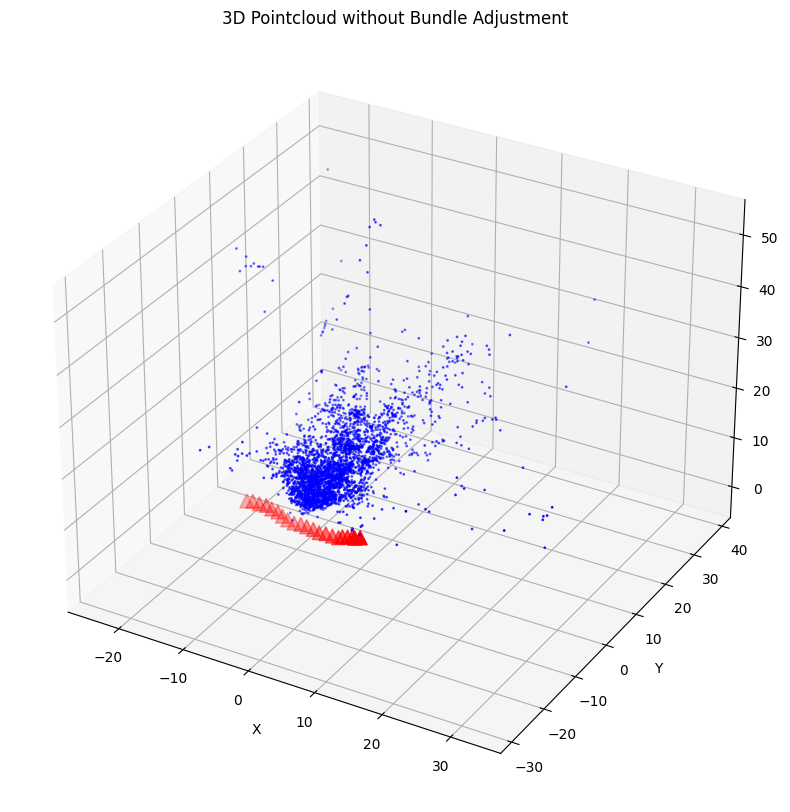

In [12]:
# Initialize the transformation matrices
transformation_matrices = [np.eye(4)]

# Initialize the object points list
all_object_points = []

# Process all image pairs
for i in range(len(images) - 1):
    src_points, dst_points, src_point_index_list, dst_point_index_list = get_match_points(
        keypoints_list[i], descriptors_list[i], keypoints_list[i+1], descriptors_list[i+1])

    rotation_matrix, translation, index_mask = get_pose_index_mask(
        dst_points, src_points)

    src_points = src_points[index_mask]
    dst_points = dst_points[index_mask]
    src_point_index_list = src_point_index_list[index_mask]
    dst_point_index_list = dst_point_index_list[index_mask]

    # Compute the transformation matrix for this pair
    current_transformation = create_transformation_matrix(rotation_matrix, translation)
    
    # Accumulate the transformation
    transformation_matrices.append(transformation_matrices[-1].dot(current_transformation))

    # Compute projection matrices
    src_projection_matrix = create_projection_matrix(transformation_matrices[i])
    dst_projection_matrix = create_projection_matrix(transformation_matrices[i+1])

    # Triangulate points
    object_points = get_object_points(src_projection_matrix, dst_projection_matrix, src_points, dst_points)
    
    # Add to the list of all object points
    all_object_points.append(object_points)

# Concatenate all object points
all_object_points = np.concatenate(all_object_points, axis=0)

# Plot the pointcloud
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot the points
ax.scatter(all_object_points[:, 0], all_object_points[:, 1], all_object_points[:, 2], c='b', s=1)

# Plot the camera positions
camera_positions = np.array([tm[:3, 3] for tm in transformation_matrices])
ax.scatter(camera_positions[:, 0], camera_positions[:, 1], camera_positions[:, 2], c='r', s=100, marker='^')

# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set title
ax.set_title('3D Pointcloud without Bundle Adjustment')

# Show the plot
plt.show()

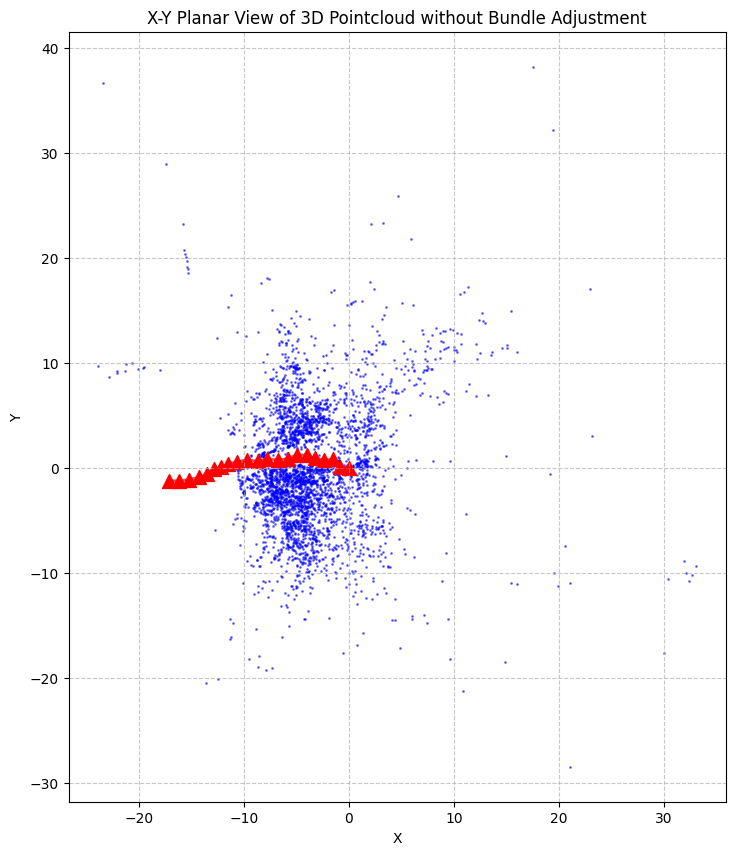

In [13]:
# Plot the top view (X-Y plane) of the pointcloud
fig, ax = plt.subplots(figsize=(10, 10))

# Plot the points
ax.scatter(all_object_points[:, 0], all_object_points[:, 1], c='b', s=1, alpha=0.5)

# Plot the camera positions
ax.scatter(camera_positions[:, 0], camera_positions[:, 1], c='r', s=100, marker='^')

# Connect camera positions with lines to show the path
ax.plot(camera_positions[:, 0], camera_positions[:, 1], c='r', linewidth=2, alpha=0.7)

# Set labels
ax.set_xlabel('X')
ax.set_ylabel('Y')

# Set title
ax.set_title('X-Y Planar View of 3D Pointcloud without Bundle Adjustment')

# Set aspect ratio to equal for a proper scale
ax.set_aspect('equal')

# Add a grid for better visualization
ax.grid(True, linestyle='--', alpha=0.7)

# Show the plot
plt.show()